# Google Colab R

- Google is now supporting a Colab notebook with the R kernel
- We can run R codes directly on Colab
- R Colab Notebook Link: [R Google Colab](https://colab.fan/r)
    - Colab with R kernel
    - With base-R installed
    - Run R codes immediately
    - No need to setup
    - Save a copy in your Drive


## Demonstration

This notebook uses the R kernel.


In [ ]:
sessionInfo()

R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.4 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] scales_1.4.0    lubridate_1.9.5 forcats_1.0.1   stringr_1.6.0  
 [5] dplyr_1.2.1     purrr_1.2.2     readr_2.2.0     tidyr_1.3.2    
 [9] tibble_3.3.1    ggplot2_4.0.3   tidy

In [ ]:
library(tidyverse)
library(lubridate)
library(ggplot2)
library(scales)

In [ ]:
system("pip install -q google-colab", intern = FALSE)

In [ ]:
hdb_raw <- read.csv('/content/HDB Resale Flat Prices.csv')

### Initial Exploratory Data Analysis (EDA)

In [ ]:
# View the first 6 rows
head(hdb_raw)

# Check the number of rows and columns
dim(hdb_raw)

# See all column names
names(hdb_raw)

# Check data types and structure
str(hdb_raw)

# Get summary statistics
summary(hdb_raw)

# Check for missing values in each column
colSums(is.na(hdb_raw))

# Other data inspections
glimpse(hdb_raw)
summary(hdb_raw)

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<int>,<chr>,<dbl>
1,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44,Improved,1979,61 years 04 months,232000
2,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67,New Generation,1978,60 years 07 months,250000
3,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67,New Generation,1980,62 years 05 months,262000
4,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68,New Generation,1980,62 years 01 month,265000
5,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67,New Generation,1980,62 years 05 months,265000
6,2017-01,ANG MO KIO,3 ROOM,150,ANG MO KIO AVE 5,01 TO 03,68,New Generation,1981,63 years,275000


[1] 242454     11

[1] "month"               "town"                "flat_type"          
 [4] "block"               "street_name"         "storey_range"       
 [7] "floor_area_sqm"      "flat_model"          "lease_commence_date"
[10] "remaining_lease"     "resale_price"

'data.frame':	242454 obs. of  11 variables:
 $ month              : chr  "2017-01" "2017-01" "2017-01" "2017-01" ...
 $ town               : chr  "ANG MO KIO" "ANG MO KIO" "ANG MO KIO" "ANG MO KIO" ...
 $ flat_type          : chr  "2 ROOM" "3 ROOM" "3 ROOM" "3 ROOM" ...
 $ block              : chr  "406" "108" "602" "465" ...
 $ street_name        : chr  "ANG MO KIO AVE 10" "ANG MO KIO AVE 4" "ANG MO KIO AVE 5" "ANG MO KIO AVE 10" ...
 $ storey_range       : chr  "10 TO 12" "01 TO 03" "01 TO 03" "04 TO 06" ...
 $ floor_area_sqm     : num  44 67 67 68 67 68 68 67 68 67 ...
 $ flat_model         : chr  "Improved" "New Generation" "New Generation" "New Generation" ...
 $ lease_commence_date: int  1979 1978 1980 1980 1980 1981 1979 1976 1979 1979 ...
 $ remaining_lease    : chr  "61 years 04 months" "60 years 07 months" "62 years 05 months" "62 years 01 month" ...
 $ resale_price       : num  232000 250000 262000 265000 265000 275000 280000 285000 285000 285000 ...


       month               town            flat_type            block       
 Length   :242454   Length   :242454   Length   :242454   Length   :242454  
 N.unique :   118   N.unique :    26   N.unique :     7   N.unique :  2788  
 N.blank  :     0   N.blank  :     0   N.blank  :     0   N.blank  :     0  
 Min.nchar:     7   Min.nchar:     5   Min.nchar:     6   Min.nchar:     1  
 Max.nchar:     7   Max.nchar:    15   Max.nchar:    16   Max.nchar:     4  
                                                                            
    street_name        storey_range    floor_area_sqm       flat_model    
 Length   :242454   Length   :242454   Min.   : 31.00   Length   :242454  
 N.unique :   580   N.unique :    17   1st Qu.: 81.00   N.unique :    21  
 N.blank  :     0   N.blank  :     0   Median : 93.00   N.blank  :     0  
 Min.nchar:     7   Min.nchar:     8   Mean   : 96.71   Min.nchar:     4  
 Max.nchar:    20   Max.nchar:     8   3rd Qu.:112.00   Max.nchar:    22  
           

month                town           flat_type               block 
                  0                   0                   0                   0 
        street_name        storey_range      floor_area_sqm          flat_model 
                  0                   0                   0                   0 
lease_commence_date     remaining_lease        resale_price 
                  0                   0                   0

Rows: 242,454
Columns: 11
$ month               <chr> "2017-01", "2017-01", "2017-01", "2017-01", "2017-…
$ town                <chr> "ANG MO KIO", "ANG MO KIO", "ANG MO KIO", "ANG MO …
$ flat_type           <chr> "2 ROOM", "3 ROOM", "3 ROOM", "3 ROOM", "3 ROOM", …
$ block               <chr> "406", "108", "602", "465", "601", "150", "447", "…
$ street_name         <chr> "ANG MO KIO AVE 10", "ANG MO KIO AVE 4", "ANG MO K…
$ storey_range        <chr> "10 TO 12", "01 TO 03", "01 TO 03", "04 TO 06", "0…
$ floor_area_sqm      <dbl> 44, 67, 67, 68, 67, 68, 68, 67, 68, 67, 68, 67, 67…
$ flat_model          <chr> "Improved", "New Generation", "New Generation", "N…
$ lease_commence_date <int> 1979, 1978, 1980, 1980, 1980, 1981, 1979, 1976, 19…
$ remaining_lease     <chr> "61 years 04 months", "60 years 07 months", "62 ye…
$ resale_price        <dbl> 232000, 250000, 262000, 265000, 265000, 275000, 28…


       month               town            flat_type            block       
 Length   :242454   Length   :242454   Length   :242454   Length   :242454  
 N.unique :   118   N.unique :    26   N.unique :     7   N.unique :  2788  
 N.blank  :     0   N.blank  :     0   N.blank  :     0   N.blank  :     0  
 Min.nchar:     7   Min.nchar:     5   Min.nchar:     6   Min.nchar:     1  
 Max.nchar:     7   Max.nchar:    15   Max.nchar:    16   Max.nchar:     4  
                                                                            
    street_name        storey_range    floor_area_sqm       flat_model    
 Length   :242454   Length   :242454   Min.   : 31.00   Length   :242454  
 N.unique :   580   N.unique :    17   1st Qu.: 81.00   N.unique :    21  
 N.blank  :     0   N.blank  :     0   Median : 93.00   N.blank  :     0  
 Min.nchar:     7   Min.nchar:     8   Mean   : 96.71   Min.nchar:     4  
 Max.nchar:    20   Max.nchar:     8   3rd Qu.:112.00   Max.nchar:    22  
           

### Data Feature Engineering & Categorisation

In [ ]:
# Import official HDB CSV
hdb_raw <- read_csv(
  "/content/HDB Resale Flat Prices.csv",
  show_col_types = FALSE
)

# Clean data types and retain 2017-2025
hdb <- hdb_raw %>%
  mutate(
    transaction_date = as.Date(paste0(month, "-01")),
    floor_area_sqm = parse_number(as.character(floor_area_sqm)),
    lease_commence_date = as.integer(lease_commence_date),
    resale_price = as.numeric(resale_price)
  ) %>%
  filter(
    between(
      transaction_date,
      as.Date("2017-01-01"),
      as.Date("2025-12-01")
    )
  ) %>%
  mutate(
    # Time features
    year = year(transaction_date),
    quarter = quarter(transaction_date),
    month_number = month(transaction_date),

    # Property characteristics
    flat_age = year - lease_commence_date,

    storey_lower = as.numeric(
      str_extract(storey_range, "^[0-9]+")
    ),
    storey_upper = as.numeric(
      str_extract(storey_range, "[0-9]+$")
    ),
    storey_midpoint = (storey_lower + storey_upper) / 2,

    floor_band = case_when(
      storey_midpoint <= 6 ~ "Low",
      storey_midpoint <= 12 ~ "Middle",
      storey_midpoint > 12 ~ "High",
      TRUE ~ NA_character_
    ),

    # Price features
    price_psm = resale_price / floor_area_sqm,

    price_band = case_when(
      is.na(resale_price) ~ NA_character_,
      resale_price >= 1000000 ~ "$1m+",
      resale_price >= 800000 ~ "$800k-$999k",
      resale_price >= 500000 ~ "$500k-$799k",
      TRUE ~ "Below $500k"
    ),

    million_dollar_flag = resale_price >= 1000000
  )


In [ ]:
# Annual summary by flat type
annual_summary <- hdb %>%
  group_by(year, flat_type) %>%
  summarise(
    transactions = n(),
    median_price = median(resale_price, na.rm = TRUE),
    median_psm = median(price_psm, na.rm = TRUE),
    million_dollar_pct = mean(
      million_dollar_flag, na.rm = TRUE
    ) * 100,
    .groups = "drop"
  )

In [ ]:
# Monthly trend for four-room flats
monthly_summary <- hdb %>%
  filter(flat_type == "4 ROOM") %>%
  group_by(transaction_date) %>%
  summarise(
    median_psm = median(price_psm, na.rm = TRUE),
    transactions = n(),
    .groups = "drop"
  ) %>%
  arrange(transaction_date) %>%
  mutate(
    previous_year_psm = lag(median_psm, 12),
    yoy_growth_pct =
      (median_psm / previous_year_psm - 1) * 100
  )

### Review, Initial Analysis and Evaluation of Dataset

In [ ]:
head(hdb)

month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,⋯,quarter,month_number,flat_age,storey_lower,storey_upper,storey_midpoint,floor_band,price_psm,price_band,million_dollar_flag
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<int>,<chr>,⋯,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<lgl>
2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44,Improved,1979,61 years 04 months,⋯,1,1,38,10,12,11,Middle,5272.727,Below $500k,FALSE
2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67,New Generation,1978,60 years 07 months,⋯,1,1,39,1,3,2,Low,3731.343,Below $500k,FALSE
2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67,New Generation,1980,62 years 05 months,⋯,1,1,37,1,3,2,Low,3910.448,Below $500k,FALSE
2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68,New Generation,1980,62 years 01 month,⋯,1,1,37,4,6,5,Low,3897.059,Below $500k,FALSE
2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67,New Generation,1980,62 years 05 months,⋯,1,1,37,1,3,2,Low,3955.224,Below $500k,FALSE
2017-01,ANG MO KIO,3 ROOM,150,ANG MO KIO AVE 5,01 TO 03,68,New Generation,1981,63 years,⋯,1,1,36,1,3,2,Low,4044.118,Below $500k,FALSE


In [ ]:
# Count missing values for every column
missing_summary <- hdb_raw %>%
  summarise(
    across(
      everything(),
      ~ sum(is.na(.x))
    )
  ) %>%
  pivot_longer(
    cols = everything(),
    names_to = "column",
    values_to = "missing_count"
  ) %>%
  mutate(
    missing_pct = round(
      missing_count / nrow(hdb) * 100, 2
    )
  ) %>%
  arrange(desc(missing_count))

View(missing_summary)


column,missing_count,missing_pct
<chr>,<int>,<dbl>
month,0,0
town,0,0
flat_type,0,0
block,0,0
street_name,0,0
storey_range,0,0
floor_area_sqm,0,0
flat_model,0,0
lease_commence_date,0,0


In [ ]:
# Investigate potential data quality issues
quality_check <- hdb %>%
  summarise(
    total_records = n(),

    missing_price = sum(is.na(resale_price)),

    missing_area = sum(is.na(floor_area_sqm)),

    invalid_area = sum(
      floor_area_sqm <= 0, na.rm = TRUE
    ),

    invalid_price = sum(
      resale_price <= 0, na.rm = TRUE
    ),

    negative_flat_age = sum(
      flat_age < 0, na.rm = TRUE
    ),

    missing_storey = sum(
      is.na(storey_midpoint)
    )
  )

print(quality_check)

# Inspect unusual property ages
age_anomalies <- hdb %>%
  filter(
    is.na(flat_age) | flat_age < 0
  )

View(age_anomalies)


# A tibble: 1 × 7
  total_records missing_price missing_area invalid_area invalid_price
          <int>         <int>        <int>        <int>         <int>
1        222066             0            0            0             0
# ℹ 2 more variables: negative_flat_age <int>, missing_storey <int>


Warning message in cbind(parts$left, chars$ellip_h, parts$right, deparse.level = 0L):
“number of rows of result is not a multiple of vector length (arg 2)”
Warning message in cbind(parts$left, chars$ellip_h, parts$right, deparse.level = 0L):
“number of rows of result is not a multiple of vector length (arg 2)”
Warning message in cbind(parts$left, chars$ellip_h, parts$right, deparse.level = 0L):
“number of rows of result is not a multiple of vector length (arg 2)”
Warning message in cbind(parts$left, chars$ellip_h, parts$right, deparse.level = 0L):
“number of rows of result is not a multiple of vector length (arg 2)”


month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,⋯,quarter,month_number,flat_age,storey_lower,storey_upper,storey_midpoint,floor_band,price_psm,price_band,million_dollar_flag
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<int>,<chr>,⋯,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<lgl>


### Dataset Validation

In [ ]:
# Filter to validate if the dataset is valid

hdb_valid <- hdb %>%
  filter(
    between(year, 2017, 2025),
    !is.na(resale_price),
    !is.na(floor_area_sqm),
    !is.na(flat_age),
    !is.na(storey_midpoint),
    !is.na(town),
    !is.na(flat_type),
    resale_price > 0,
    floor_area_sqm > 0,
    flat_age >= 0
  )

# Compare before and after filtering
nrow(hdb)
nrow(hdb_valid)

# Calculate percentage of records retained
round(nrow(hdb_valid) / nrow(hdb) * 100, 2)

[1] 222066

[1] 222066

[1] 100

### Exploratory Data Analysis (EDA)

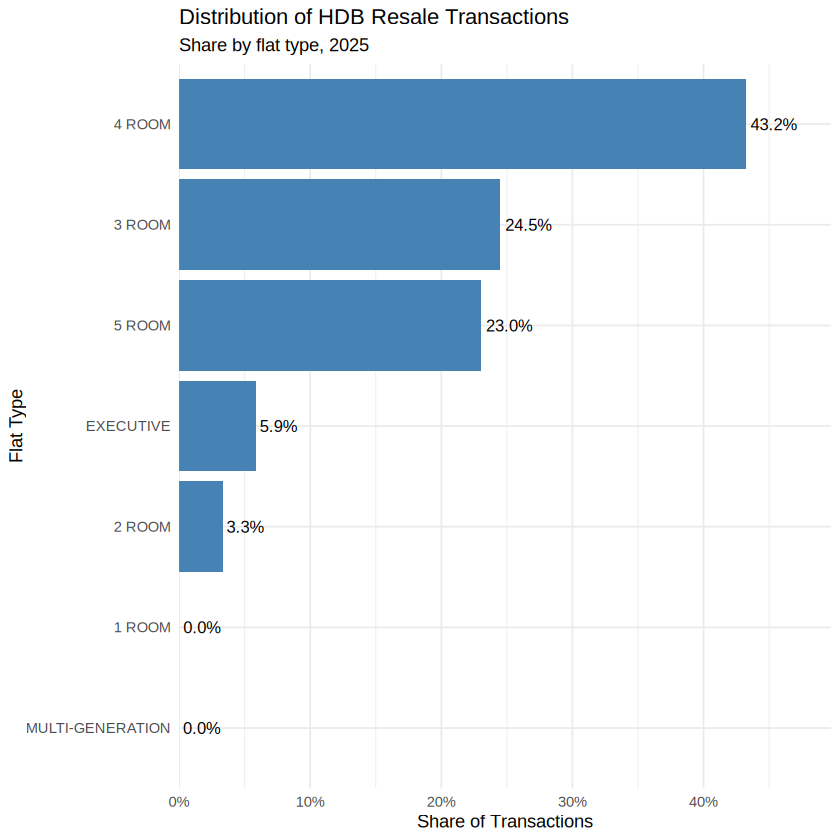

In [ ]:
# Distribution of HDB resale transactions by flat type
flat_type_distribution <- hdb %>%
  filter(year == 2025) %>%
  count(flat_type, name = "transactions") %>%
  mutate(
    share = transactions / sum(transactions)
  )

ggplot(
  flat_type_distribution,
  aes(
    x = reorder(flat_type, share),
    y = share
  )
) +
  geom_col(fill = "steelblue") +
  geom_text(
    aes(label = percent(share, accuracy = 0.1)),
    hjust = -0.1,
    size = 3.5
  ) +
  coord_flip() +
  scale_y_continuous(
    labels = label_percent(),
    expand = expansion(mult = c(0, 0.15))
  ) +
  labs(
    title = "Distribution of HDB Resale Transactions",
    subtitle = "Share by flat type, 2025",
    x = "Flat Type",
    y = "Share of Transactions"
  ) +
  theme_minimal()


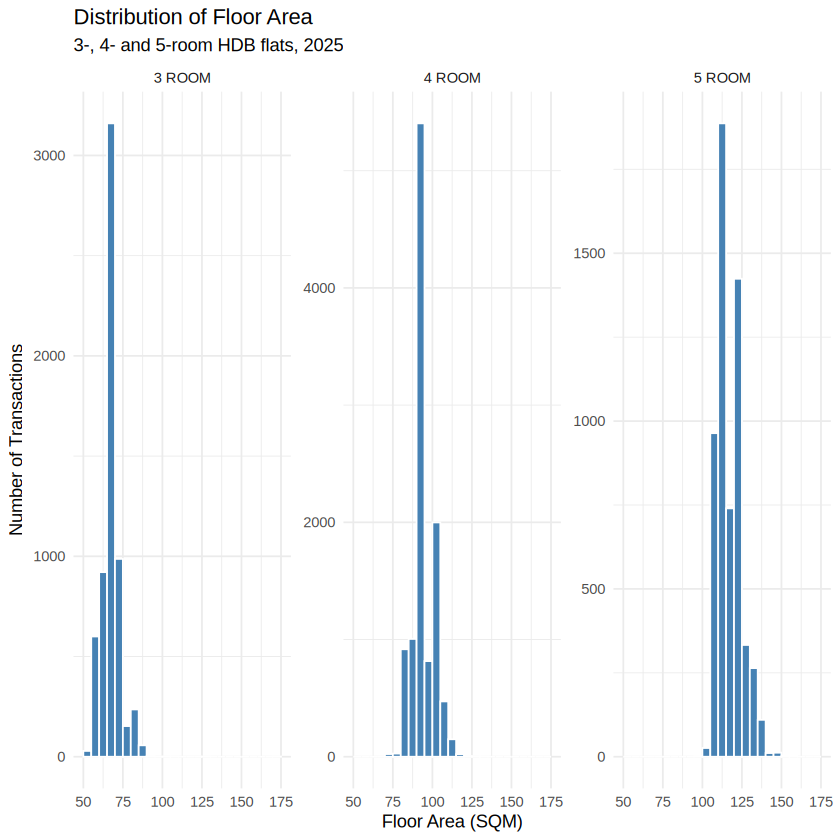

In [ ]:
# Distribution of floor area by flat type

area_data <- hdb %>%
  filter(
    year == 2025,
    flat_type %in% c(
      "3 ROOM", "4 ROOM", "5 ROOM"
    )
  )

ggplot(
  area_data,
  aes(x = floor_area_sqm)
) +
  geom_histogram(
    binwidth = 5,
    boundary = 0,
    fill = "steelblue",
    color = "white"
  ) +
  facet_wrap(
    ~ flat_type,
    ncol = 3,
    scales = "free_y"
  ) +
  labs(
    title = "Distribution of Floor Area",
    subtitle = "3-, 4- and 5-room HDB flats, 2025",
    x = "Floor Area (SQM)",
    y = "Number of Transactions"
  ) +
  theme_minimal()

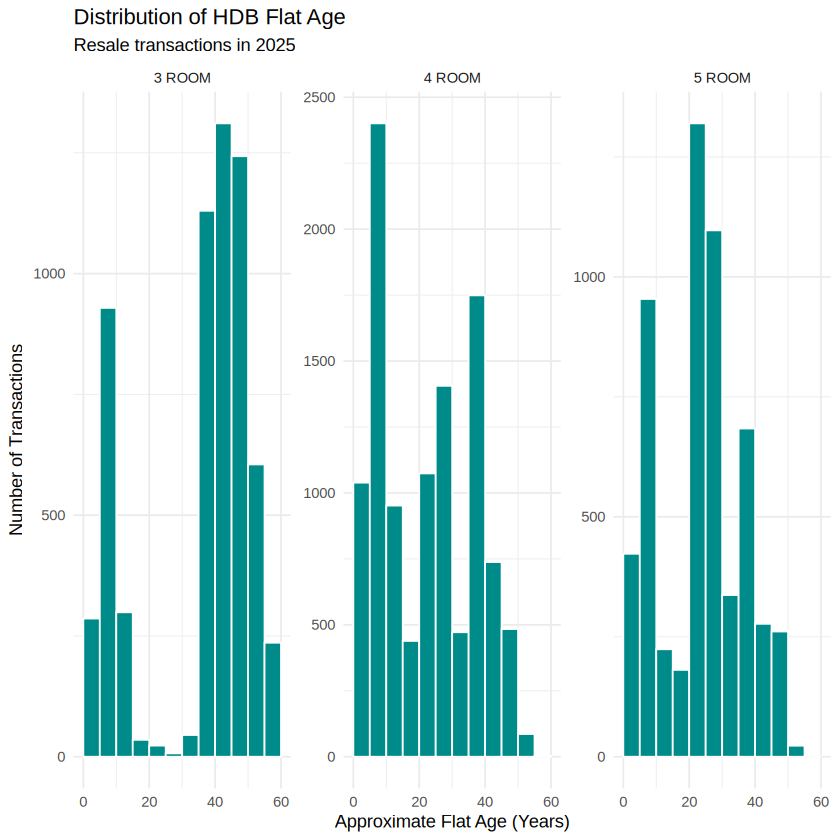

In [ ]:
# Distribution of flat age

age_data <- hdb %>%
  filter(
    year == 2025,
    flat_type %in% c(
      "3 ROOM", "4 ROOM", "5 ROOM"
    )
  )

ggplot(
  age_data,
  aes(x = flat_age)
) +
  geom_histogram(
    binwidth = 5,
    boundary = 0,
    fill = "darkcyan",
    color = "white"
  ) +
  facet_wrap(
    ~ flat_type,
    ncol = 3,
    scales = "free_y"
  ) +
  labs(
    title = "Distribution of HDB Flat Age",
    subtitle = "Resale transactions in 2025",
    x = "Approximate Flat Age (Years)",
    y = "Number of Transactions"
  ) +
  theme_minimal()


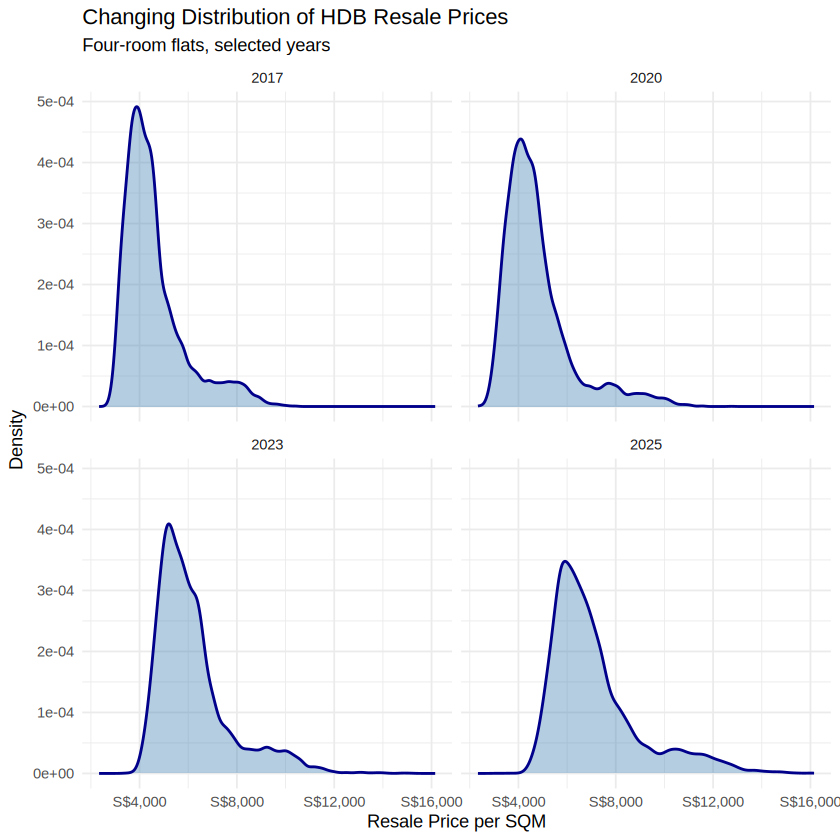

In [ ]:
# Compare four-room resale price distributions over time

price_distribution_year <- hdb %>%
  filter(
    flat_type == "4 ROOM",
    year %in% c(2017, 2020, 2023, 2025)
  )

ggplot(
  price_distribution_year,
  aes(x = price_psm)
) +
  geom_density(
    fill = "steelblue",
    color = "darkblue",
    alpha = 0.4,
    linewidth = 0.8
  ) +
  facet_wrap(
    ~ year,
    ncol = 2
  ) +
  scale_x_continuous(
    labels = label_dollar(prefix = "S$")
  ) +
  labs(
    title = "Changing Distribution of HDB Resale Prices",
    subtitle = "Four-room flats, selected years",
    x = "Resale Price per SQM",
    y = "Density"
  ) +
  theme_minimal()


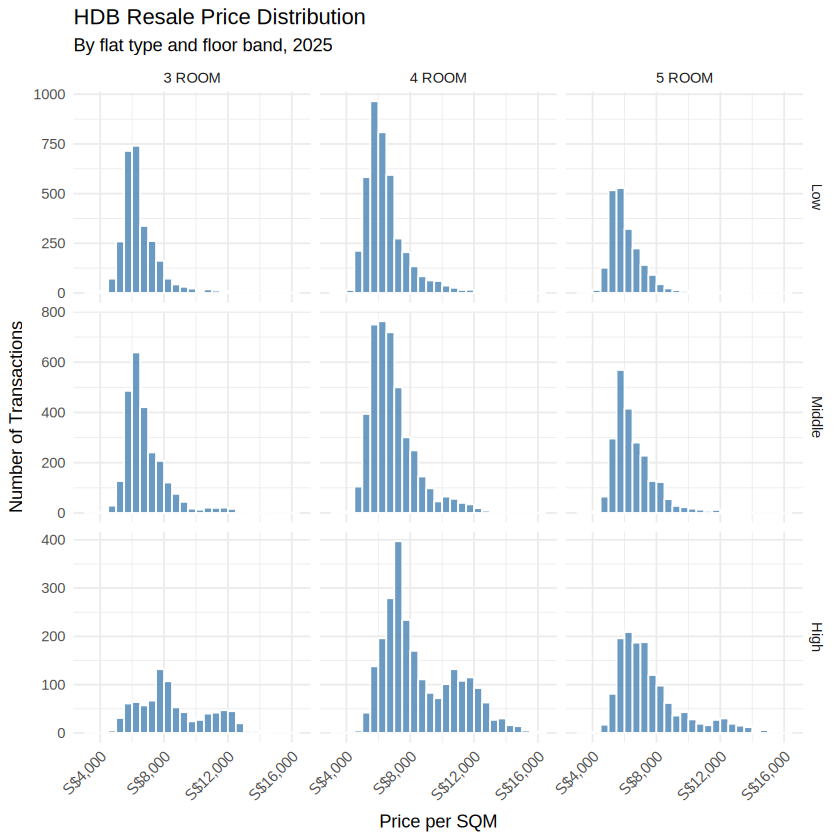

In [ ]:

# Compare price distributions by flat type and floor band

grid_data <- hdb %>%
  filter(
    year == 2025,
    flat_type %in% c(
      "3 ROOM", "4 ROOM", "5 ROOM"
    ),
    !is.na(floor_band),
    is.finite(price_psm),
    price_psm > 0
  ) %>%
  mutate(
    floor_band = factor(
      floor_band,
      levels = c("Low", "Middle", "High")
    )
  )

ggplot(
  grid_data,
  aes(x = price_psm)
) +
  geom_histogram(
    binwidth = 500,
    boundary = 0,
    fill = "steelblue",
    color = "white",
    alpha = 0.8
  ) +
  facet_grid(
    rows = vars(floor_band),
    cols = vars(flat_type),
    scales = "free_y"
  ) +
  scale_x_continuous(
    labels = label_dollar(prefix = "S$")
  ) +
  labs(
    title = "HDB Resale Price Distribution",
    subtitle = "By flat type and floor band, 2025",
    x = "Price per SQM",
    y = "Number of Transactions"
  ) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(
      angle = 45,
      hjust = 1
    )
  )


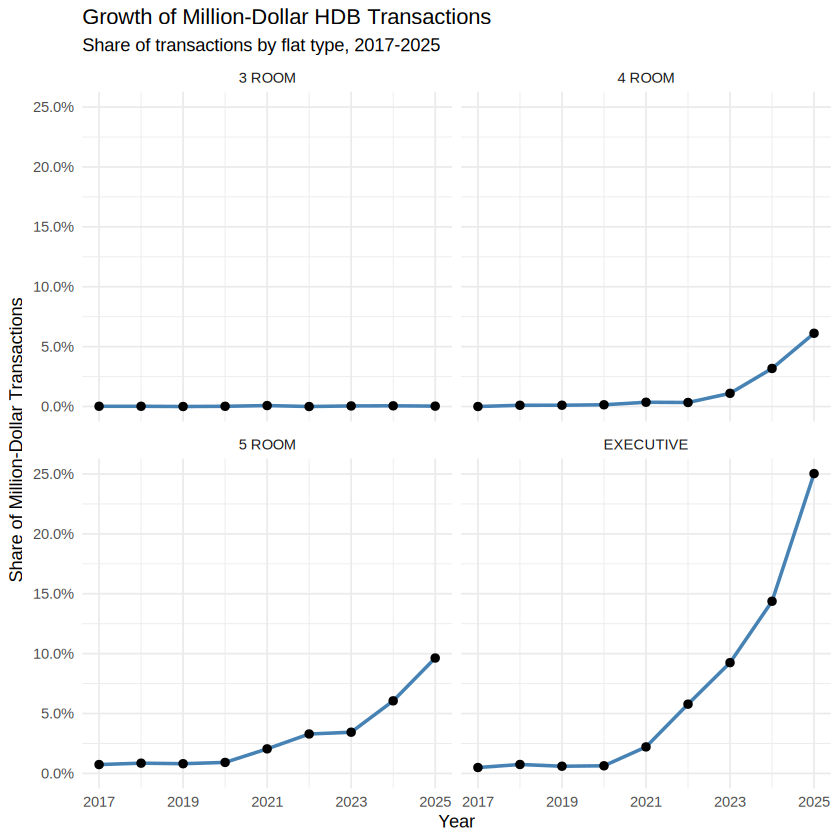

In [ ]:
# Million-dollar transaction share by flat type

million_by_type <- hdb %>%
  filter(
    flat_type %in% c(
      "3 ROOM", "4 ROOM",
      "5 ROOM", "EXECUTIVE"
    )
  ) %>%
  group_by(year, flat_type) %>%
  summarise(
    transactions = n(),
    million_sales = sum(million_dollar_flag),
    million_share = mean(million_dollar_flag),
    .groups = "drop"
  ) %>%
  filter(transactions >= 50)

ggplot(
  million_by_type,
  aes(
    x = year,
    y = million_share
  )
) +
  geom_line(
    color = "steelblue",
    linewidth = 1
  ) +
  geom_point(size = 2) +
  facet_wrap(
    ~ flat_type,
    ncol = 2
  ) +
  scale_x_continuous(
    breaks = seq(2017, 2025, by = 2)
  ) +
  scale_y_continuous(
    labels = label_percent(accuracy = 0.1)
  ) +
  labs(
    title = "Growth of Million-Dollar HDB Transactions",
    subtitle = "Share of transactions by flat type, 2017-2025",
    x = "Year",
    y = "Share of Million-Dollar Transactions"
  ) +
  theme_minimal()


### Data Visualisations

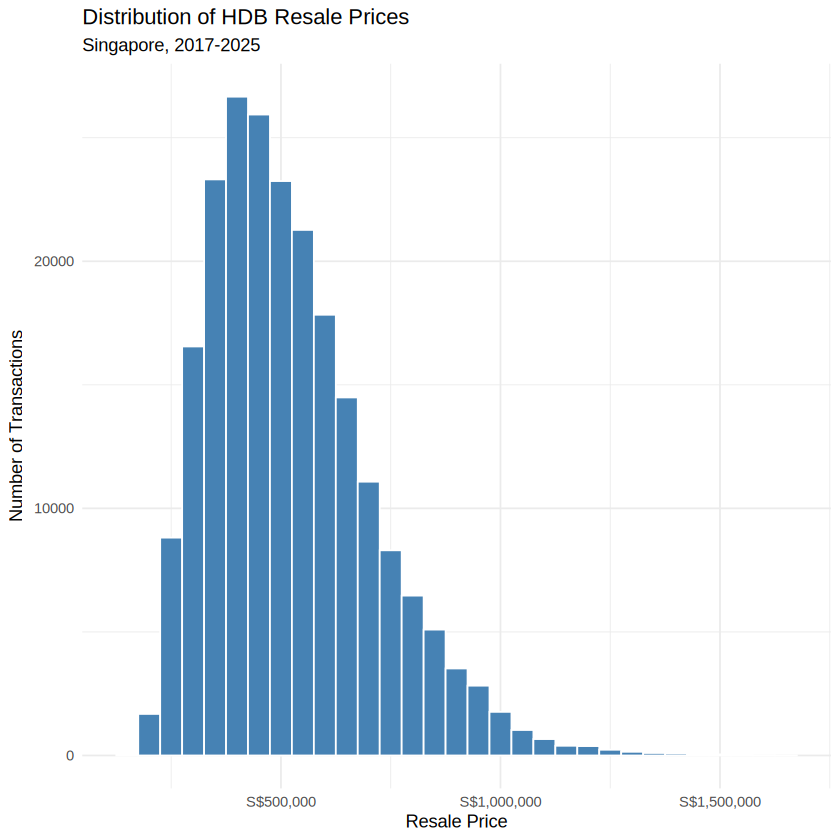

In [ ]:
# Histogram visualisation of Distribution of HDB resale prices

ggplot(
  hdb,
  aes(x = resale_price)
) +
  geom_histogram(
    binwidth = 50000,
    fill = "steelblue",
    color = "white"
  ) +
  scale_x_continuous(
    labels = label_dollar(prefix = "S$")
  ) +
  labs(
    title = "Distribution of HDB Resale Prices",
    subtitle = "Singapore, 2017-2025",
    x = "Resale Price",
    y = "Number of Transactions"
  ) +
  theme_minimal()

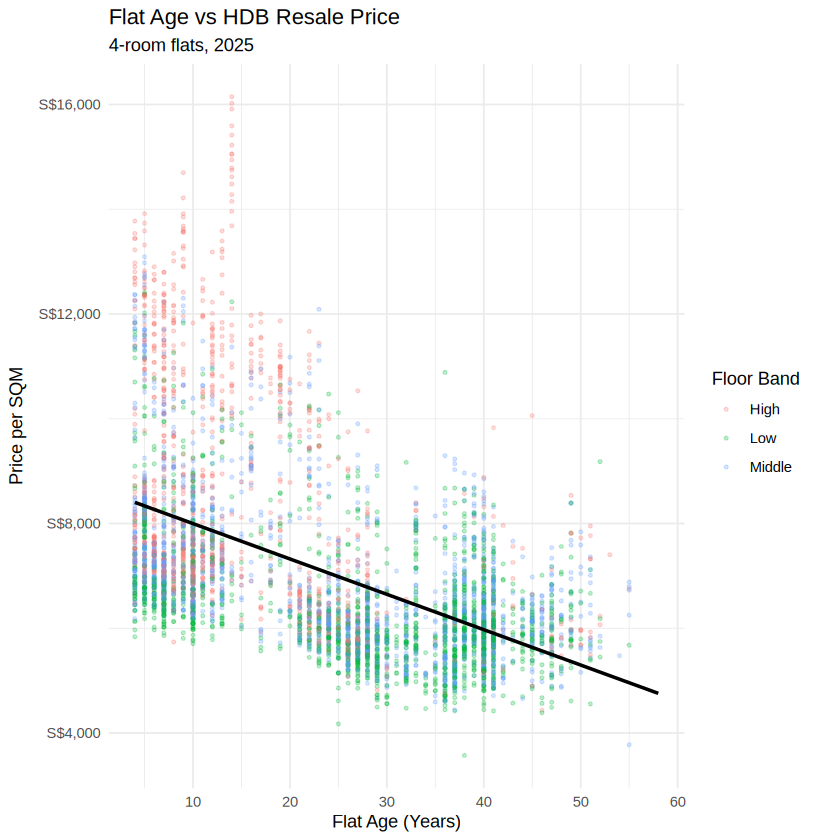

In [ ]:
# Visualisize scatterplot of price vs flat age

# Step 1: Filter for comparable properties
scatter_data <- hdb %>%
  filter(
    year == 2025,
    flat_type == "4 ROOM",
    !is.na(flat_age),
    is.finite(price_psm),
    !is.na(floor_band)
  )

# Step 2: Sample points for readability
set.seed(5344)

sample_n <- min(5000, nrow(scatter_data))

scatter_sample <- scatter_data %>%
  slice_sample(n = sample_n)

# Step 3: Build scatterplot
ggplot(
  scatter_data,
  aes(x = flat_age, y = price_psm)
) +
  geom_point(
    data = scatter_sample,
    aes(color = floor_band),
    alpha = 0.25,
    size = 0.8
  ) +
  geom_smooth(
    method = "lm",
    formula = y ~ x,
    se = FALSE,
    color = "black",
    linewidth = 1
  ) +
  scale_y_continuous(
    labels = label_dollar(prefix = "S$")
  ) +
  labs(
    title = "Flat Age vs HDB Resale Price",
    subtitle = "4-room flats, 2025",
    x = "Flat Age (Years)",
    y = "Price per SQM",
    color = "Floor Band"
  ) +
  theme_minimal()

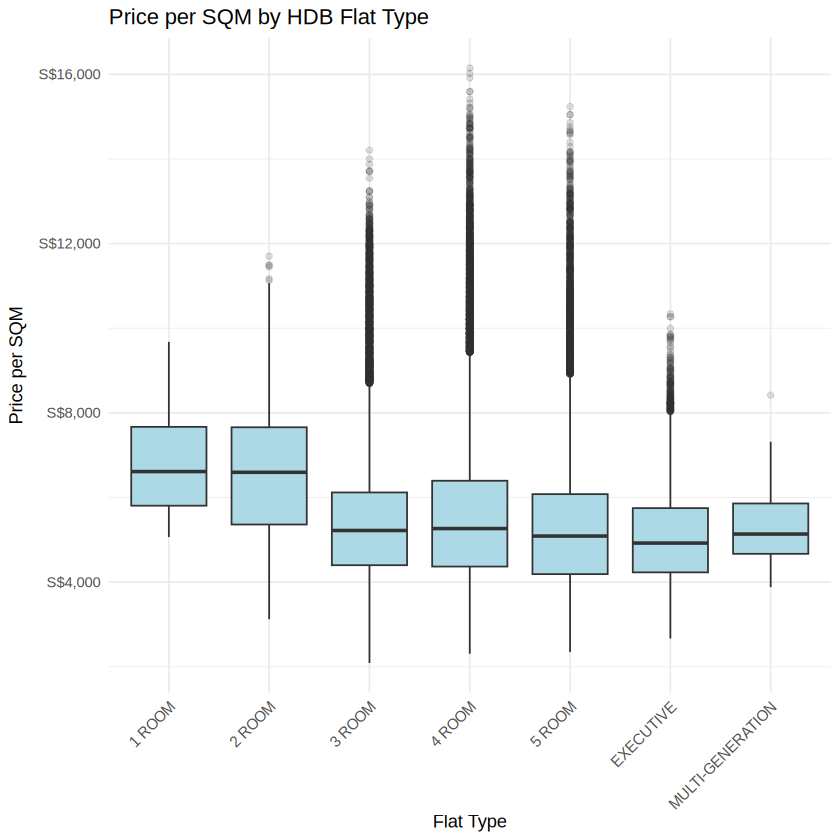

In [ ]:
# Boxplot visualisation of Price differences across flat types

ggplot(
  hdb,
  aes(
    x = flat_type,
    y = price_psm
  )
) +
  geom_boxplot(
    fill = "lightblue",
    outlier.alpha = 0.15
  ) +
  scale_y_continuous(
    labels = label_dollar(prefix = "S$")
  ) +
  labs(
    title = "Price per SQM by HDB Flat Type",
    x = "Flat Type",
    y = "Price per SQM"
  ) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(
      angle = 45,
      hjust = 1
    )
  )


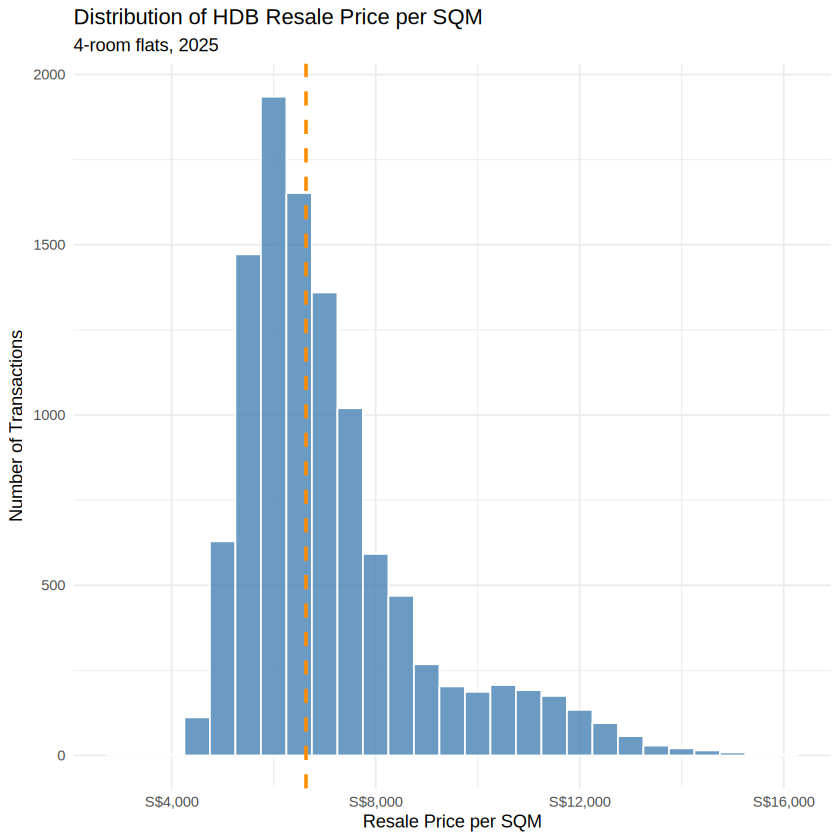

In [ ]:
# Histogram visualisation of Distribution of price per sqm

# Step 1: Prepare the histogram dataset
hist_data <- hdb_valid %>%
  filter(
    year == 2025,
    flat_type == "4 ROOM",
    is.finite(price_psm),
    price_psm > 0
  )

# Step 2: Calculate median PSM
median_psm <- median(hist_data$price_psm)

# Step 3: Plot histogram
ggplot(hist_data, aes(x = price_psm)) +

  geom_histogram(
    binwidth = 500,
    fill = "steelblue",
    color = "white",
    alpha = 0.8
  ) +

  # Reference line for median PSM
  geom_vline(
    xintercept = median_psm,
    color = "darkorange",
    linetype = "dashed",
    linewidth = 1
  ) +

  scale_x_continuous(
    labels = label_dollar(prefix = "S$")
  ) +

  labs(
    title = "Distribution of HDB Resale Price per SQM",
    subtitle = "4-room flats, 2025",
    x = "Resale Price per SQM",
    y = "Number of Transactions"
  ) +

  theme_minimal()

In [ ]:
# Histogram summary

hist_summary <- hist_data %>%
  summarise(
    transactions = n(),
    mean_psm = mean(price_psm),
    median_psm = median(price_psm),
    sd_psm = sd(price_psm),
    min_psm = min(price_psm),
    max_psm = max(price_psm),
    p25 = quantile(price_psm, 0.25),
    p75 = quantile(price_psm, 0.75)
  )

print(hist_summary)

# A tibble: 1 × 8
  transactions mean_psm median_psm sd_psm min_psm max_psm   p25   p75
         <int>    <dbl>      <dbl>  <dbl>   <dbl>   <dbl> <dbl> <dbl>
1        10843    7121.      6634.  1822.   3118.  16149. 5870. 7730.


In [ ]:
# Tabulate the contribution of each town to resale transaction volume

town_contribution <- hdb %>%
  filter(year == 2025) %>%
  group_by(town) %>%
  summarise(
    transactions = n(),
    total_sales_value = sum(resale_price),
    .groups = "drop"
  ) %>%
  mutate(
    transaction_share =
      transactions / sum(transactions),

    value_share =
      total_sales_value / sum(total_sales_value)
  ) %>%
  arrange(desc(transaction_share))

View(town_contribution)


town,transactions,total_sales_value,transaction_share,value_share
<chr>,<int>,<dbl>,<dbl>,<dbl>
TAMPINES,1921,1368425503,0.076582682,0.083603441
SENGKANG,1905,1272464784,0.075944825,0.077740757
WOODLANDS,1748,1064546961,0.069685856,0.065038096
YISHUN,1703,959022583,0.067891883,0.058591123
JURONG WEST,1591,897907346,0.063426886,0.054857311
PUNGGOL,1538,1040263951,0.061313985,0.063554534
HOUGANG,1313,823193958,0.052344124,0.050292725
BUKIT BATOK,1304,793837586,0.051985329,0.048499208
BEDOK,1207,723735003,0.048118322,0.044216317


In [ ]:
# Feature engineer cumulative share

# Aggregate transactions by town for 2025
town_combo <- hdb_valid %>%
  filter(year == 2025) %>%
  count(town, name = "transactions") %>%
  arrange(desc(transactions)) %>%
  mutate(
    transaction_share = transactions / sum(transactions),
    cumulative_share = cumsum(transaction_share),
    town = factor(town, levels = town)
  )

View(town_combo)

town,transactions,transaction_share,cumulative_share
<fct>,<int>,<dbl>,<dbl>
TAMPINES,1921,0.076582682,0.07658268
SENGKANG,1905,0.075944825,0.15252751
WOODLANDS,1748,0.069685856,0.22221336
YISHUN,1703,0.067891883,0.29010525
JURONG WEST,1591,0.063426886,0.35353213
PUNGGOL,1538,0.061313985,0.41484612
HOUGANG,1313,0.052344124,0.46719024
BUKIT BATOK,1304,0.051985329,0.51917557
BEDOK,1207,0.048118322,0.56729389


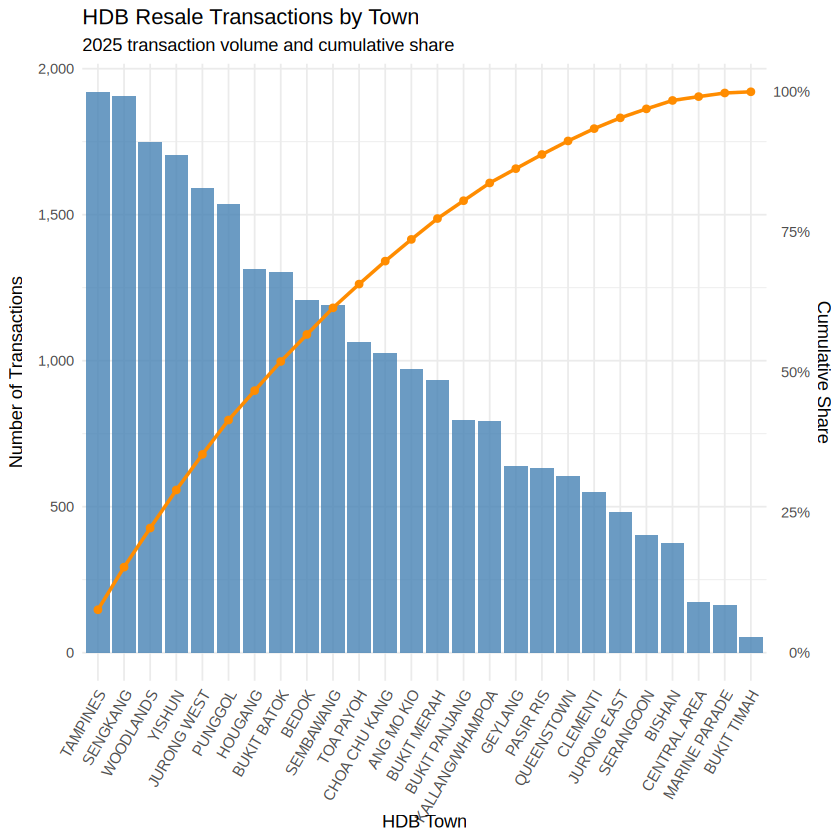

In [ ]:
# Combo chart visualisation of Town contributions to resale transaction volume

# Scaling factor for secondary axis
scale_factor <- max(town_combo$transactions)

ggplot(town_combo, aes(x = town)) +

  # Bars: transaction volume
  geom_col(
    aes(y = transactions),
    fill = "steelblue",
    alpha = 0.8
  ) +

  # Line: cumulative transaction share
  geom_line(
    aes(
      y = cumulative_share * scale_factor,
      group = 1
    ),
    color = "darkorange",
    linewidth = 1
  ) +

  geom_point(
    aes(y = cumulative_share * scale_factor),
    color = "darkorange",
    size = 1.8
  ) +

  # Primary and secondary axes
  scale_y_continuous(
    name = "Number of Transactions",
    labels = comma,
    sec.axis = sec_axis(
      ~ . / scale_factor,
      name = "Cumulative Share",
      labels = label_percent()
    )
  ) +

  labs(
    title = "HDB Resale Transactions by Town",
    subtitle = "2025 transaction volume and cumulative share",
    x = "HDB Town"
  ) +

  theme_minimal() +
  theme(
    axis.text.x = element_text(
      angle = 60,
      hjust = 1
    )
  )


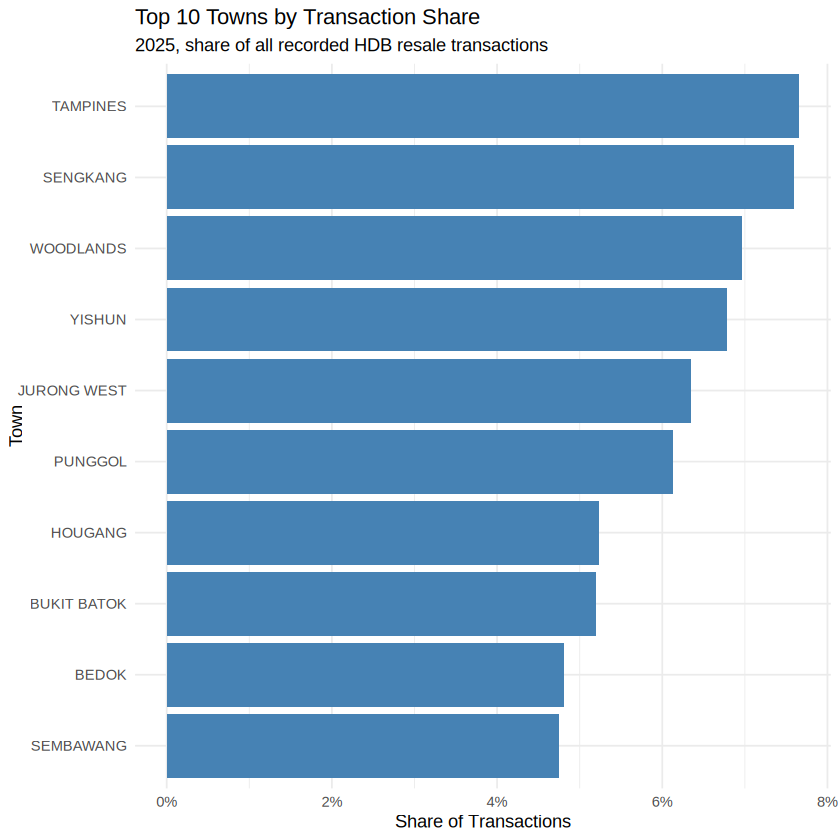

In [ ]:
# Visualise the top ten towns by bar

top_10_towns <- town_contribution %>%
  slice_max(
    order_by = transaction_share,
    n = 10
  )

ggplot(
  top_10_towns,
  aes(
    x = reorder(town, transaction_share),
    y = transaction_share
  )
) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  scale_y_continuous(
    labels = label_percent()
  ) +
  labs(
    title = "Top 10 Towns by Transaction Share",
    subtitle = "2025, share of all recorded HDB resale transactions",
    x = "Town",
    y = "Share of Transactions"
  ) +
  theme_minimal()


In [ ]:
# Aggregate median PSM by town and year

heatmap_data <- hdb %>%
  filter(
    flat_type == "4 ROOM",
    between(year, 2017, 2025),
    is.finite(price_psm)
  ) %>%
  group_by(town, year) %>%
  summarise(
    median_psm = median(price_psm),
    transactions = n(),
    .groups = "drop"
  ) %>%
  # Suppress unstable cells with very few transactions
  filter(transactions >= 20) %>%
  mutate(
    town = fct_reorder(
      town, median_psm, .fun = median
    )
  )

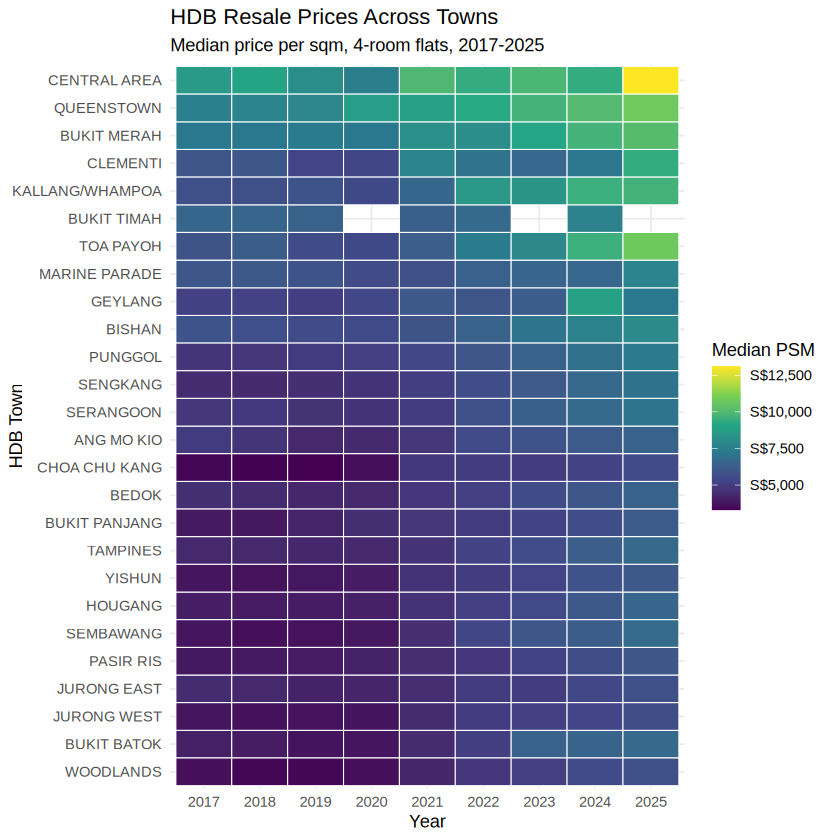

In [ ]:
# Heatmap of resale prices across towns

ggplot(
  heatmap_data,
  aes(
    x = factor(year),
    y = town,
    fill = median_psm
  )
) +
  geom_tile(
    color = "white",
    linewidth = 0.3
  ) +
  scale_fill_viridis_c(
    labels = label_dollar(prefix = "S$")
  ) +
  labs(
    title = "HDB Resale Prices Across Towns",
    subtitle = "Median price per sqm, 4-room flats, 2017-2025",
    x = "Year",
    y = "HDB Town",
    fill = "Median PSM"
  ) +
  theme_minimal()

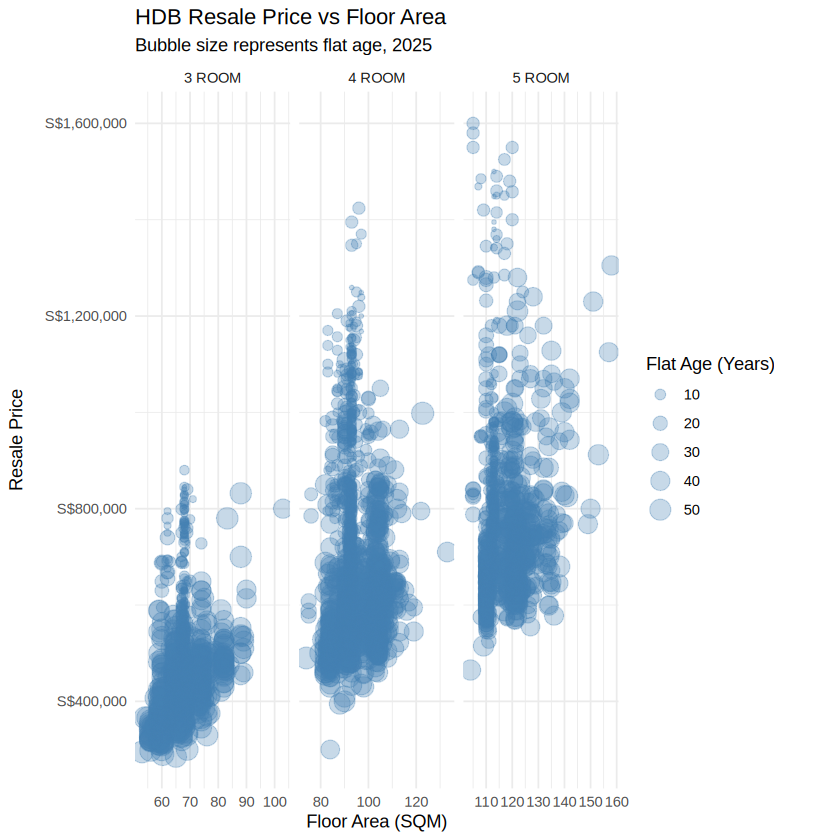

In [ ]:
# Bubble chart of resale price versus floor area versus flat age

# Step 1: Select relevant flat types
bubble_data <- hdb_valid %>%
  filter(
    year == 2025,
    flat_type %in% c(
      "3 ROOM", "4 ROOM", "5 ROOM"
    ),
    is.finite(floor_area_sqm),
    is.finite(resale_price),
    !is.na(flat_age),
    flat_age >= 0
  )

# Step 2: Random sampling to reduce overplotting
set.seed(5344)

sample_size <- min(4000, nrow(bubble_data))

bubble_sample <- bubble_data %>%
  slice_sample(n = sample_size)

# Step 3: Create bubble chart
ggplot(
  bubble_sample,
  aes(
    x = floor_area_sqm,
    y = resale_price,
    size = flat_age
  )
) +

  geom_point(
    color = "steelblue",
    alpha = 0.3
  ) +

  # Bubble size represents flat age
  scale_size_continuous(
    range = c(1, 6),
    name = "Flat Age (Years)"
  ) +

  # Compare flat types in separate panels
  facet_wrap(
    ~ flat_type,
    scales = "free_x"
  ) +

  scale_y_continuous(
    labels = label_dollar(prefix = "S$")
  ) +

  labs(
    title = "HDB Resale Price vs Floor Area",
    subtitle = "Bubble size represents flat age, 2025",
    x = "Floor Area (SQM)",
    y = "Resale Price"
  ) +

  theme_minimal()

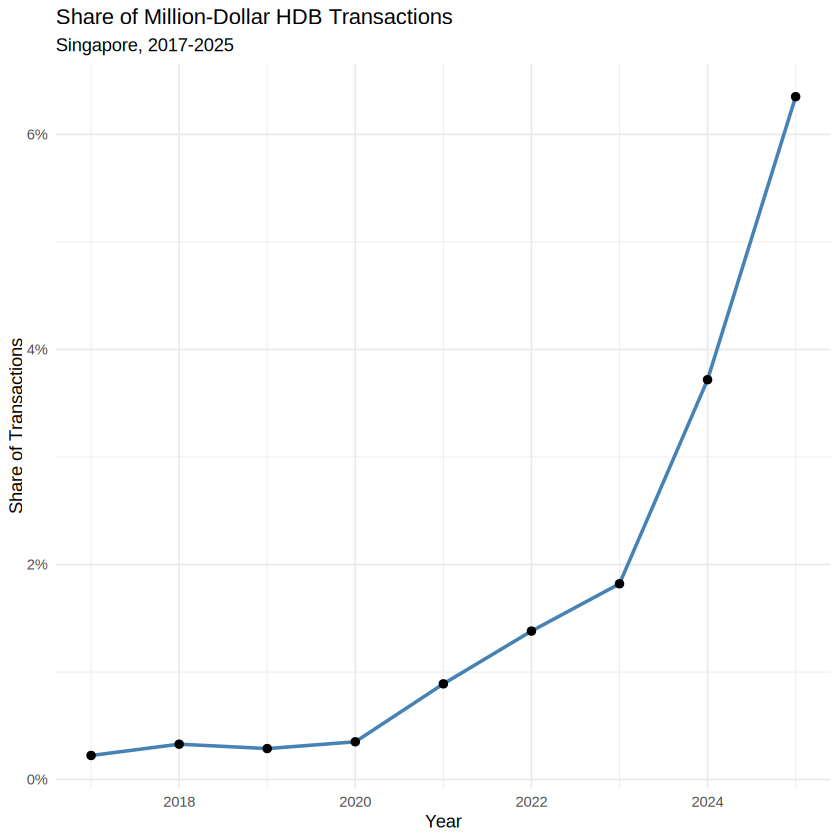

In [ ]:
# Line chart visualisation of growth of million-dollar HDB transactions

million_dollar_trend <- hdb %>%
  group_by(year) %>%
  summarise(
    total_transactions = n(),

    million_dollar_sales = sum(
      million_dollar_flag, na.rm = TRUE
    ),

    million_dollar_share =
      million_dollar_sales / total_transactions,

    .groups = "drop"
  )

ggplot(
  million_dollar_trend,
  aes(
    x = year,
    y = million_dollar_share
  )
) +
  geom_line(
    color = "steelblue",
    linewidth = 1
  ) +
  geom_point(size = 2) +
  scale_y_continuous(
    labels = label_percent()
  ) +
  labs(
    title = "Share of Million-Dollar HDB Transactions",
    subtitle = "Singapore, 2017-2025",
    x = "Year",
    y = "Share of Transactions"
  ) +
  theme_minimal()


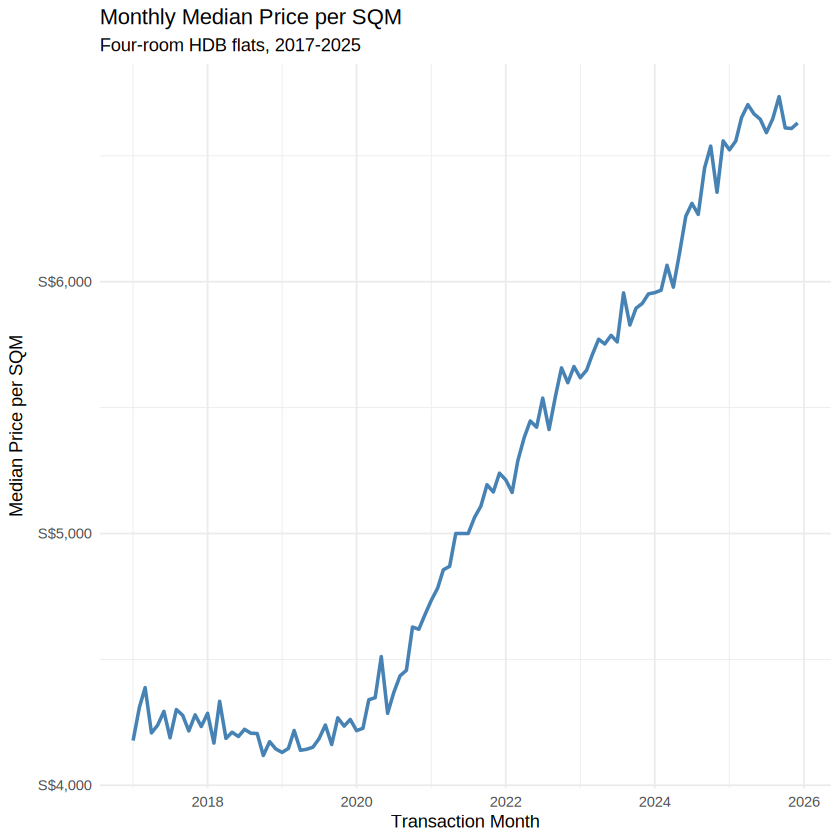

In [ ]:
# Line chart visualisation of Historical price trends

monthly_prices <- hdb %>%
  filter(flat_type == "4 ROOM") %>%
  group_by(transaction_date) %>%
  summarise(
    median_psm = median(price_psm),
    transactions = n(),
    .groups = "drop"
  ) %>%
  arrange(transaction_date)

ggplot(
  monthly_prices,
  aes(
    x = transaction_date,
    y = median_psm
  )
) +
  geom_line(
    color = "steelblue",
    linewidth = 1
  ) +
  scale_y_continuous(
    labels = label_dollar(prefix = "S$")
  ) +
  labs(
    title = "Monthly Median Price per SQM",
    subtitle = "Four-room HDB flats, 2017-2025",
    x = "Transaction Month",
    y = "Median Price per SQM"
  ) +
  theme_minimal()


### Statistical and predictive modelling

### Multiple linear regression, Logistic regression and Time-series trend and seasonality regression

#### Research questions:
- What property characteristics predict resale price?
- What predicts whether a flat sells for at least $1 million?
- Can historical monthly prices predict future monthly prices?

In [ ]:
# Model 1. Predicting HDB resale prices using lm()

# Prepare modelling dataset
hdb_model <- hdb %>%
  filter(
    is.finite(resale_price),
    is.finite(floor_area_sqm),
    !is.na(flat_age),
    !is.na(storey_midpoint),
    !is.na(town),
    !is.na(flat_type)
  ) %>%
  mutate(year = as.integer(year))

# Chronological train/test split
train <- hdb_model %>%
  filter(year <= 2024)

test <- hdb_model %>%
  filter(year == 2025)

# Handle categories absent from training
test <- test %>%
  filter(
    town %in% unique(train$town),
    flat_type %in% unique(train$flat_type)
  )

# Build multiple linear regression
price_model <- lm(
  resale_price ~
    floor_area_sqm +
    flat_age +
    storey_midpoint +
    town +
    flat_type +
    year,
  data = train
)

# Inspect coefficients and model statistics
summary(price_model)

# Predict 2025 resale prices
test <- test %>%
  mutate(
    predicted_price = as.numeric(
      predict(price_model, newdata = test)
    ),
    prediction_error = resale_price - predicted_price,
    absolute_error = abs(prediction_error)
  )

# Evaluate performance
model_performance <- test %>%
  summarise(
    MAE = mean(absolute_error),
    RMSE = sqrt(mean(prediction_error^2))
  )

print(model_performance)


Call:
lm(formula = resale_price ~ floor_area_sqm + flat_age + storey_midpoint + 
    town + flat_type + year, data = train)

Residuals:
    Min      1Q  Median      3Q     Max 
-388986  -47014   -5170   40548  578055 

Coefficients:
                            Estimate Std. Error  t value Pr(>|t|)    
(Intercept)               -6.293e+07  1.423e+05 -442.209  < 2e-16 ***
floor_area_sqm             4.206e+03  2.373e+01  177.258  < 2e-16 ***
flat_age                  -5.307e+03  1.516e+01 -350.176  < 2e-16 ***
storey_midpoint            5.049e+03  2.954e+01  170.940  < 2e-16 ***
townBEDOK                 -2.229e+04  1.040e+03  -21.439  < 2e-16 ***
townBISHAN                 9.544e+04  1.425e+03   66.959  < 2e-16 ***
townBUKIT BATOK           -1.011e+05  1.118e+03  -90.398  < 2e-16 ***
townBUKIT MERAH            8.918e+04  1.130e+03   78.949  < 2e-16 ***
townBUKIT PANJANG         -1.546e+05  1.162e+03 -133.104  < 2e-16 ***
townBUKIT TIMAH            1.879e+05  3.265e+03   57.569  < 2e-16 

# A tibble: 1 × 2
     MAE   RMSE
   <dbl>  <dbl>
1 63938. 91140.


flat_type,transactions,MAE
<chr>,<int>,<dbl>
MULTI-GENERATION,4,160492.54
EXECUTIVE,1470,106392.91
5 ROOM,5781,74084.70
4 ROOM,10843,60539.57
3 ROOM,6149,52816.96
1 ROOM,5,51794.44
2 ROOM,832,44513.10


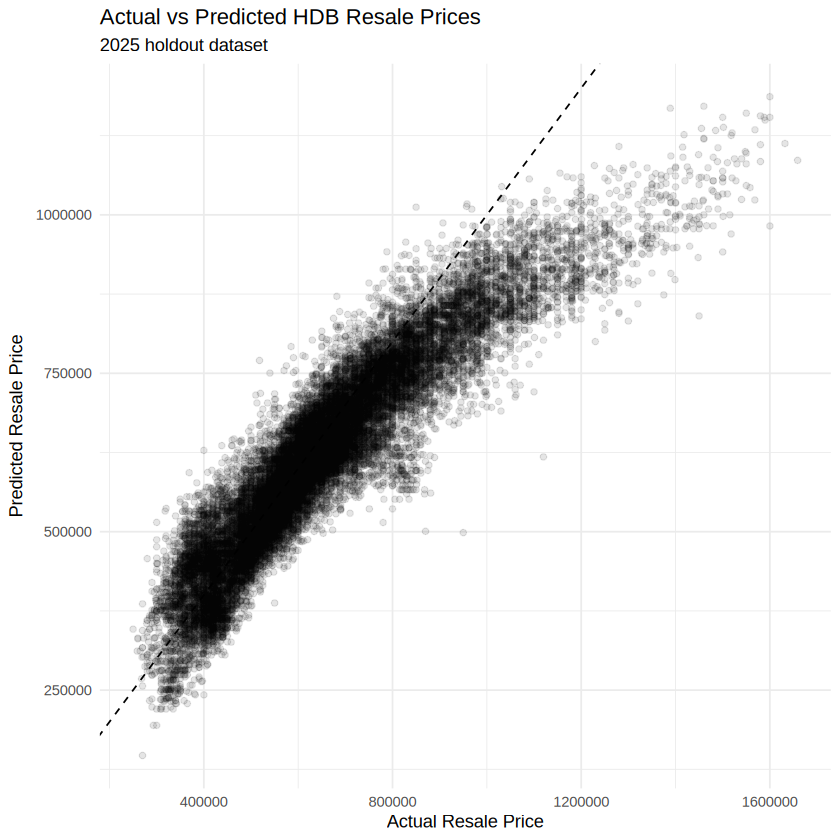

In [ ]:
# Identify where prediction errors are largest
error_by_flat_type <- test %>%
  group_by(flat_type) %>%
  summarise(
    transactions = n(),
    MAE = mean(absolute_error),
    .groups = "drop"
  ) %>%
  arrange(desc(MAE))

View(error_by_flat_type)

# Compare predicted against actual prices
ggplot(
  test,
  aes(x = resale_price, y = predicted_price)
) +
  geom_point(alpha = 0.1) +
  geom_abline(
    slope = 1,
    intercept = 0,
    linetype = "dashed"
  ) +
  labs(
    title = "Actual vs Predicted HDB Resale Prices",
    subtitle = "2025 holdout dataset",
    x = "Actual Resale Price",
    y = "Predicted Resale Price"
  ) +
  theme_minimal()


In [ ]:
# Model 2. Predicting million-dollar HDB transactions using glm()

# Check the distribution of the target
table(train$million_dollar_flag)

# Build logistic regression
premium_model <- glm(
  million_dollar_flag ~
    floor_area_sqm +
    flat_age +
    storey_midpoint +
    town +
    flat_type +
    year,
  data = train,
  family = binomial()
)

summary(premium_model)

# Predict probabilities for 2025
test <- test %>%
  mutate(
    premium_probability = as.numeric(
      predict(
        premium_model,
        newdata = test,
        type = "response"
      )
    )
  )

# Evaluate probability prediction quality
brier_score <- mean(
  (
    as.numeric(test$million_dollar_flag) -
    test$premium_probability
  )^2
)

print(brier_score)



 FALSE   TRUE 
194587   2395 

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”



Call:
glm(formula = million_dollar_flag ~ floor_area_sqm + flat_age + 
    storey_midpoint + town + flat_type + year, family = binomial(), 
    data = train)

Coefficients:
                            Estimate Std. Error z value Pr(>|z|)    
(Intercept)               -2.706e+03  4.873e+03  -0.555   0.5787    
floor_area_sqm             1.565e-01  5.094e-03  30.731  < 2e-16 ***
flat_age                  -2.237e-01  6.034e-03 -37.069  < 2e-16 ***
storey_midpoint            1.343e-01  4.075e-03  32.965  < 2e-16 ***
townBEDOK                 -1.984e+00  2.369e-01  -8.375  < 2e-16 ***
townBISHAN                 1.980e+00  1.761e-01  11.242  < 2e-16 ***
townBUKIT BATOK           -6.209e+00  3.937e-01 -15.772  < 2e-16 ***
townBUKIT MERAH            1.471e+00  1.590e-01   9.250  < 2e-16 ***
townBUKIT PANJANG         -4.541e+00  3.660e-01 -12.406  < 2e-16 ***
townBUKIT TIMAH            4.408e+00  2.803e-01  15.729  < 2e-16 ***
townCENTRAL AREA           5.536e+00  2.121e-01  26.107  < 2e-16 **

[1] 0.02263483


In [ ]:
# Model 3. Simple time-series forecasting

# Prepare monthly time-series features
monthly_model <- monthly_prices %>%
  arrange(transaction_date) %>%
  mutate(
    year = lubridate::year(transaction_date),
    month_number = lubridate::month(transaction_date),
    time_index = row_number(),
    seasonal_naive = lag(median_psm, 12)
  )

# Verify all 108 calendar months are present
stopifnot(nrow(monthly_model) == 108)

ts_train <- monthly_model %>%
  filter(year <= 2024)

ts_test <- monthly_model %>%
  filter(year == 2025)

# Fit a simple trend and seasonal model
ts_model <- lm(
  median_psm ~ time_index + factor(month_number),
  data = ts_train
)

# Generate holdout predictions
ts_test <- ts_test %>%
  mutate(
    forecast = as.numeric(
      predict(ts_model, newdata = ts_test)
    )
  )

# Compare model to seasonal naive benchmark
ts_performance <- ts_test %>%
  summarise(
    model_MAE = mean(abs(median_psm - forecast)),
    naive_MAE = mean(abs(median_psm - seasonal_naive))
  )

print(ts_performance)

# A tibble: 1 × 2
  model_MAE naive_MAE
      <dbl>     <dbl>
1      286.      396.


In [ ]:
# Install forecast packages
install.packages("forecast")

# Load packages
library(forecast)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘zoo’, ‘RcppArmadillo’




In [ ]:
# Step 1. Prepare the monthly time series

# Prepare data in chronological order
arima_data <- monthly_prices %>%
  arrange(transaction_date) %>%
  select(transaction_date, median_psm)

# Check every calendar month exists
expected_months <- seq.Date(
  from = as.Date("2017-01-01"),
  to = as.Date("2025-12-01"),
  by = "month"
)

stopifnot(
  identical(arima_data$transaction_date, expected_months),
  all(is.finite(arima_data$median_psm))
)

# Training: Jan 2017-Dec 2024
train_ts <- ts(
  arima_data %>%
    filter(transaction_date < as.Date("2025-01-01")) %>%
    pull(median_psm),
  start = c(2017, 1),
  frequency = 12
)

# Testing: Jan-Dec 2025
test_ts <- ts(
  arima_data %>%
    filter(transaction_date >= as.Date("2025-01-01")) %>%
    pull(median_psm),
  start = c(2025, 1),
  frequency = 12
)

Series: train_ts 
ARIMA(0,2,2) 

Coefficients:
          ma1     ma2
      -1.5880  0.6862
s.e.   0.0705  0.0731

sigma^2 = 5063:  log likelihood = -534.99
AIC=1075.98   AICc=1076.24   BIC=1083.61

Training set error measures:
                   ME     RMSE      MAE        MPE     MAPE      MASE
Training set 3.319512 69.65602 52.42757 0.04918677 1.061272 0.1669189
                    ACF1
Training set -0.00895783


	Ljung-Box test

data:  Residuals from ARIMA(0,2,2)
Q* = 12.341, df = 17, p-value = 0.7791

Model df: 2.   Total lags used: 19



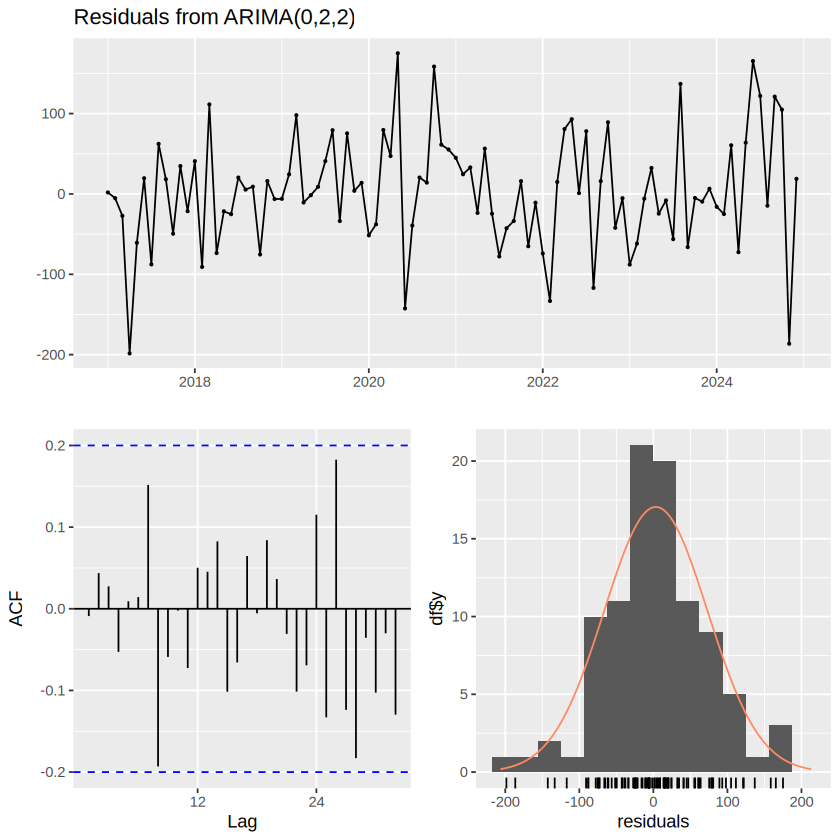

In [ ]:
# Step 2. Fit the ARIMA model

# Select an ARIMA specification using training data
arima_model <- auto.arima(
  train_ts,
  seasonal = TRUE,
  stepwise = TRUE,
  approximation = FALSE
)

# Inspect selected model and coefficients
summary(arima_model)

# Check residual autocorrelation
checkresiduals(arima_model)

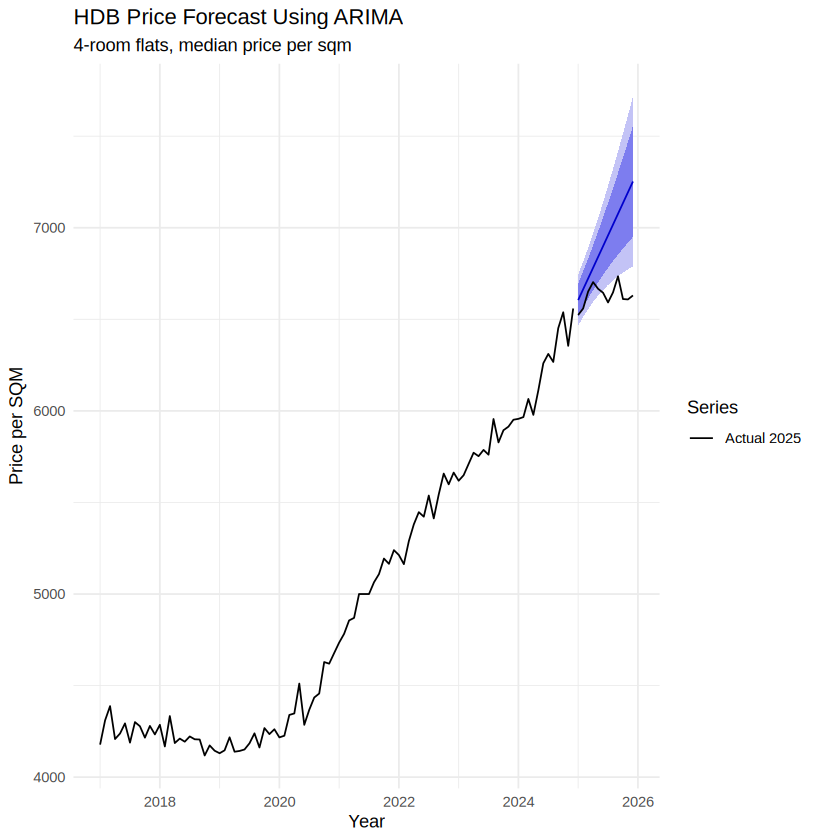

In [ ]:
# Step 3. Forecast 2025 and visualise the result

# Predict 12 months beyond the end of 2024
arima_forecast <- forecast(
  arima_model,
  h = 12,
  level = c(80, 95)
)

# Visualise forecast versus actual 2025
autoplot(arima_forecast) +
  autolayer(
    test_ts,
    series = "Actual 2025"
  ) +
  scale_color_manual(
    values = c("Actual 2025" = "black")
  ) +
  labs(
    title = "HDB Price Forecast Using ARIMA",
    subtitle = "4-room flats, median price per sqm",
    x = "Year",
    y = "Price per SQM",
    colour = "Series"
  ) +
  theme_minimal()

In [ ]:
# Step 4. Compare ARIMA against a baseline

# Seasonal naive forecast
naive_forecast <- snaive(
  train_ts,
  h = 12
)

# Evaluate against 2025 actual observations
arima_accuracy <- accuracy(
  arima_forecast, test_ts
)

naive_accuracy <- accuracy(
  naive_forecast, test_ts
)

# Extract test performance
arima_metrics <- arima_accuracy[
  "Test set", c("MAE", "RMSE")
]

naive_metrics <- naive_accuracy[
  "Test set", c("MAE", "RMSE")
]

comparison <- tibble(
  Model = c("ARIMA", "Seasonal Naive"),
  MAE = c(
    arima_metrics["MAE"],
    naive_metrics["MAE"]
  ),
  RMSE = c(
    arima_metrics["RMSE"],
    naive_metrics["RMSE"]
  )
)

print(comparison)

# A tibble: 2 × 3
  Model            MAE  RMSE
  <chr>          <dbl> <dbl>
1 ARIMA           298.  355.
2 Seasonal Naive  396.  445.
